In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("CareFlow - Process Performance Analysis")
print("Libraries imported successfully!")

CareFlow - Process Performance Analysis
Libraries imported successfully!


In [2]:
event_log_df = pd.read_csv("careflow_normalized_event_log.csv")

# Convert Timestamp into datetime format
event_log_df["Timestamp"] = pd.to_datetime(
    event_log_df["Timestamp"],
    errors="coerce"
)

print("Normalized event log loaded successfully!")
print("Dataset shape:", event_log_df.shape)
print("Total cases:", event_log_df["Case_ID"].nunique())
print("Total activities:", event_log_df["Activity_Name"].nunique())

display(event_log_df.head(10))

Normalized event log loaded successfully!
Dataset shape: (148686, 3)
Total cases: 49912
Total activities: 5


,Case_ID,Activity_Name,Timestamp
0,112508,Appointment,2024-10-28 05:46:00
1,112508,Prescription,2025-10-03 06:46:00
2,124174,Appointment,2024-11-14 05:46:00
3,124174,Prescription,2024-11-26 06:44:00
4,139157,Appointment,2024-12-09 14:51:00
5,139157,Prescription,2025-08-25 06:03:00
6,142459,Appointment,2024-12-16 07:41:00
7,142459,Prescription,2024-12-17 04:48:00
8,142985,Appointment,2024-12-17 03:59:00
9,142985,Prescription,2024-12-17 04:24:00


In [3]:
# Sort events chronologically within each case
event_log_df = event_log_df.sort_values(
    ["Case_ID", "Timestamp", "Activity_Name"]
).reset_index(drop=True)

# Get the next activity and timestamp within each case
event_log_df["Next_Activity"] = (
    event_log_df.groupby("Case_ID")["Activity_Name"].shift(-1)
)

event_log_df["Next_Timestamp"] = (
    event_log_df.groupby("Case_ID")["Timestamp"].shift(-1)
)

# Calculate time between consecutive activities in minutes
event_log_df["Waiting_Time_Minutes"] = (
    event_log_df["Next_Timestamp"] - event_log_df["Timestamp"]
).dt.total_seconds() / 60

# Keep only rows with a next activity
transition_df = event_log_df.dropna(
    subset=["Next_Activity", "Next_Timestamp"]
).copy()

print("Transition analysis prepared successfully!")
print("Total transitions:", len(transition_df))

display(
    transition_df[
        [
            "Case_ID",
            "Activity_Name",
            "Next_Activity",
            "Timestamp",
            "Next_Timestamp",
            "Waiting_Time_Minutes"
        ]
    ].head(10)
)

Transition analysis prepared successfully!
Total transitions: 98774


,Case_ID,Activity_Name,Next_Activity,Timestamp,Next_Timestamp,Waiting_Time_Minutes
0,317,Appointment,Prescription,2024-04-25 11:12:00,2024-04-26 05:15:00,1083.0
2,756,Appointment,Prescription,2024-04-27 12:32:00,2025-08-23 14:35:00,695643.0
4,1694,Appointment,Prescription,2024-04-29 13:37:00,2024-05-02 11:24:00,4187.0
6,2182,Appointment,Prescription,2024-04-30 10:30:00,2024-04-30 11:01:00,31.0
8,2948,Appointment,Prescription,2024-05-02 06:10:00,2024-05-02 06:40:00,30.0
10,7744,Appointment,Prescription,2024-05-09 12:50:00,2024-05-09 13:50:00,60.0
12,26427,Appointment,Prescription,2024-06-11 03:57:00,2024-06-11 05:45:00,108.0
14,28225,Appointment,Prescription,2024-06-14 06:29:00,2024-06-14 06:33:00,4.0
16,39207,Appointment,Prescription,2024-07-08 09:46:00,2024-07-08 10:17:00,31.0
18,42222,Appointment,Prescription,2024-07-13 05:54:00,2024-07-13 06:20:00,26.0


In [4]:
transition_summary = (
    transition_df
    .groupby(["Activity_Name", "Next_Activity"])
    .agg(
        Transition_Count=("Waiting_Time_Minutes", "count"),
        Average_Waiting_Time_Minutes=("Waiting_Time_Minutes", "mean"),
        Median_Waiting_Time_Minutes=("Waiting_Time_Minutes", "median"),
        Minimum_Waiting_Time_Minutes=("Waiting_Time_Minutes", "min"),
        Maximum_Waiting_Time_Minutes=("Waiting_Time_Minutes", "max")
    )
    .reset_index()
)

transition_summary = transition_summary.sort_values(
    "Average_Waiting_Time_Minutes",
    ascending=False
)

print("Transition waiting-time analysis completed!")

display(transition_summary.round(2))

Transition waiting-time analysis completed!


,Activity_Name,Next_Activity,Transition_Count,Average_Waiting_Time_Minutes,Median_Waiting_Time_Minutes,Minimum_Waiting_Time_Minutes,Maximum_Waiting_Time_Minutes
16,Prescription,Appointment,5,2107.40,1439.0,6.0,5704.0
9,Lab,Imaging,481,1613.12,60.0,2.0,76329.0
17,Prescription,Imaging,2975,443.31,36.0,1.0,65759.0
12,Lab,Prescription,385,250.68,35.0,0.0,10170.0
13,Pharmacy,Imaging,1,245.00,245.0,245.0,245.0
8,Lab,Appointment,125,192.80,158.0,1.0,686.0
3,Appointment,Prescription,47939,130.26,25.0,0.0,695643.0
2,Appointment,Lab,358,109.53,30.0,0.0,9388.0
5,Imaging,Imaging,184,88.02,0.0,0.0,12514.0
1,Appointment,Imaging,1600,72.02,46.5,0.0,2314.0


In [5]:
# Identify transitions above 24 hours
unusual_transitions = transition_df[
    transition_df["Waiting_Time_Minutes"] > 1440
].copy()

print("Unusual transition analysis completed!")
print("Transitions above 24 hours:", len(unusual_transitions))

print("\nTop 10 largest recorded time gaps:")

display(
    unusual_transitions.sort_values(
        "Waiting_Time_Minutes",
        ascending=False
    )[
        [
            "Case_ID",
            "Activity_Name",
            "Next_Activity",
            "Waiting_Time_Minutes"
        ]
    ].head(10)
)

Unusual transition analysis completed!
Transitions above 24 hours: 589

Top 10 largest recorded time gaps:


,Case_ID,Activity_Name,Next_Activity,Waiting_Time_Minutes
2,756,Appointment,Prescription,695643.0
6244,276617,Appointment,Prescription,525630.0
22,112508,Appointment,Prescription,489660.0
26,139157,Appointment,Prescription,372432.0
9476,292361,Appointment,Prescription,310206.0
27600,317869,Prescription,Prescription,171329.0
9013,289967,Appointment,Prescription,96749.0
2703,260121,Appointment,Prescription,92582.0
2716,260851,Appointment,Prescription,90453.0
109641,405650,Prescription,Prescription,82625.0


In [6]:
# Keep transitions with recorded gaps from 0 to 24 hours
filtered_transition_df = transition_df[
    (transition_df["Waiting_Time_Minutes"] >= 0) &
    (transition_df["Waiting_Time_Minutes"] <= 1440)
].copy()

filtered_summary = (
    filtered_transition_df
    .groupby(["Activity_Name", "Next_Activity"])
    .agg(
        Transition_Count=("Waiting_Time_Minutes", "count"),
        Average_Waiting_Time_Minutes=("Waiting_Time_Minutes", "mean"),
        Median_Waiting_Time_Minutes=("Waiting_Time_Minutes", "median")
    )
    .reset_index()
    .sort_values(
        "Average_Waiting_Time_Minutes",
        ascending=False
    )
)

print("Filtered transition analysis completed!")
print("Original transitions:", len(transition_df))
print("Filtered transitions:", len(filtered_transition_df))
print("Excluded transitions:", len(transition_df) - len(filtered_transition_df))

display(filtered_summary.round(2))

Filtered transition analysis completed!
Original transitions: 98774
Filtered transitions: 98185
Excluded transitions: 589


,Activity_Name,Next_Activity,Transition_Count,Average_Waiting_Time_Minutes,Median_Waiting_Time_Minutes
16,Prescription,Appointment,3,667.00,556.0
13,Pharmacy,Imaging,1,245.00,245.0
8,Lab,Appointment,125,192.80,158.0
12,Lab,Prescription,369,107.00,33.0
9,Lab,Imaging,409,106.12,52.0
1,Appointment,Imaging,1599,70.61,46.0
2,Appointment,Lab,354,59.14,29.5
4,Imaging,Appointment,288,55.14,18.0
17,Prescription,Imaging,2850,53.85,34.0
11,Lab,Pharmacy,2,45.00,45.0


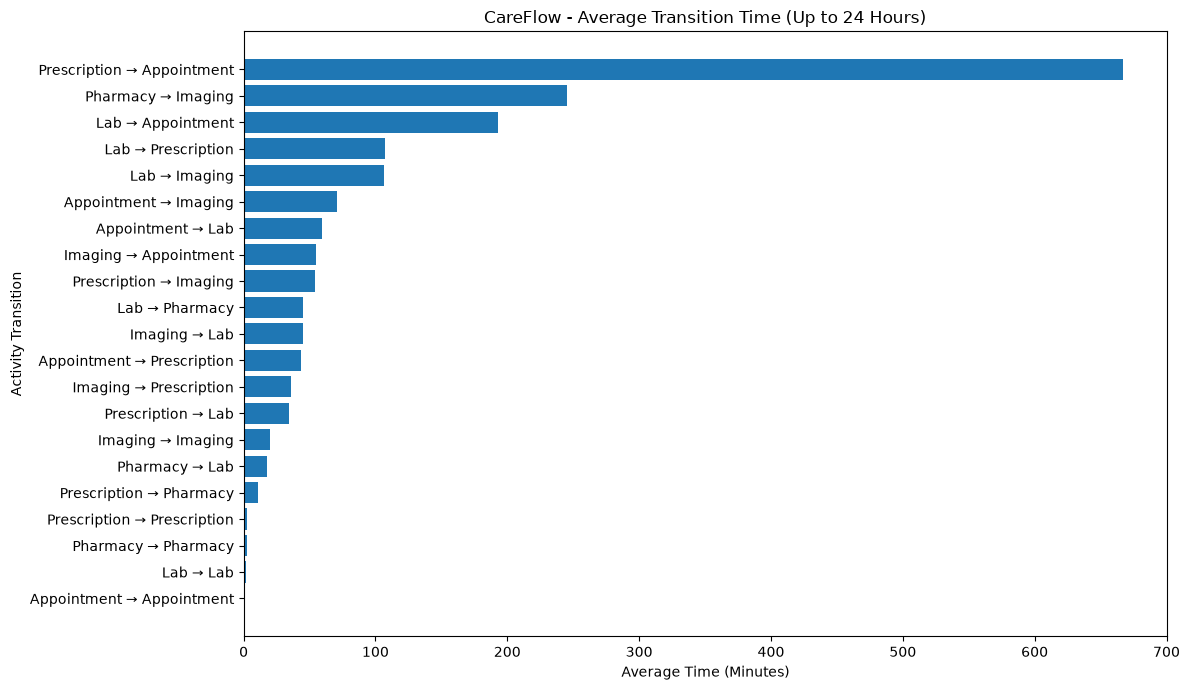

Transition waiting-time chart saved successfully!


In [7]:
plt.figure(figsize=(12, 7))

chart_data = filtered_summary.sort_values(
    "Average_Waiting_Time_Minutes",
    ascending=True
)

labels = (
    chart_data["Activity_Name"]
    + " → "
    + chart_data["Next_Activity"]
)

plt.barh(
    labels,
    chart_data["Average_Waiting_Time_Minutes"]
)

plt.xlabel("Average Time (Minutes)")
plt.ylabel("Activity Transition")
plt.title("CareFlow - Average Transition Time (Up to 24 Hours)")

plt.tight_layout()

plt.savefig(
    "careflow_transition_waiting_time_chart.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Transition waiting-time chart saved successfully!")

In [8]:
transition_summary.to_csv(
    "careflow_transition_waiting_time_summary.csv",
    index=False
)

print("Full transition waiting-time summary saved successfully!")
print("Rows:", len(transition_summary))
display(transition_summary.head(10))

Full transition waiting-time summary saved successfully!
Rows: 21


,Activity_Name,Next_Activity,Transition_Count,Average_Waiting_Time_Minutes,Median_Waiting_Time_Minutes,Minimum_Waiting_Time_Minutes,Maximum_Waiting_Time_Minutes
16,Prescription,Appointment,5,2107.400000,1439.0,6.0,5704.0
9,Lab,Imaging,481,1613.116424,60.0,2.0,76329.0
17,Prescription,Imaging,2975,443.311597,36.0,1.0,65759.0
12,Lab,Prescription,385,250.677922,35.0,0.0,10170.0
13,Pharmacy,Imaging,1,245.000000,245.0,245.0,245.0
8,Lab,Appointment,125,192.800000,158.0,1.0,686.0
3,Appointment,Prescription,47939,130.255116,25.0,0.0,695643.0
2,Appointment,Lab,358,109.530726,30.0,0.0,9388.0
5,Imaging,Imaging,184,88.021739,0.0,0.0,12514.0
1,Appointment,Imaging,1600,72.015000,46.5,0.0,2314.0


In [9]:
filtered_summary.to_csv(
    "careflow_process_performance_summary.csv",
    index=False
)

print("Filtered process performance summary saved successfully!")
print("Rows:", len(filtered_summary))
display(filtered_summary.head(10))

Filtered process performance summary saved successfully!
Rows: 21


,Activity_Name,Next_Activity,Transition_Count,Average_Waiting_Time_Minutes,Median_Waiting_Time_Minutes
16,Prescription,Appointment,3,667.000000,556.0
13,Pharmacy,Imaging,1,245.000000,245.0
8,Lab,Appointment,125,192.800000,158.0
12,Lab,Prescription,369,107.002710,33.0
9,Lab,Imaging,409,106.122249,52.0
1,Appointment,Imaging,1599,70.612883,46.0
2,Appointment,Lab,354,59.135593,29.5
4,Imaging,Appointment,288,55.135417,18.0
17,Prescription,Imaging,2850,53.849825,34.0
11,Lab,Pharmacy,2,45.000000,45.0


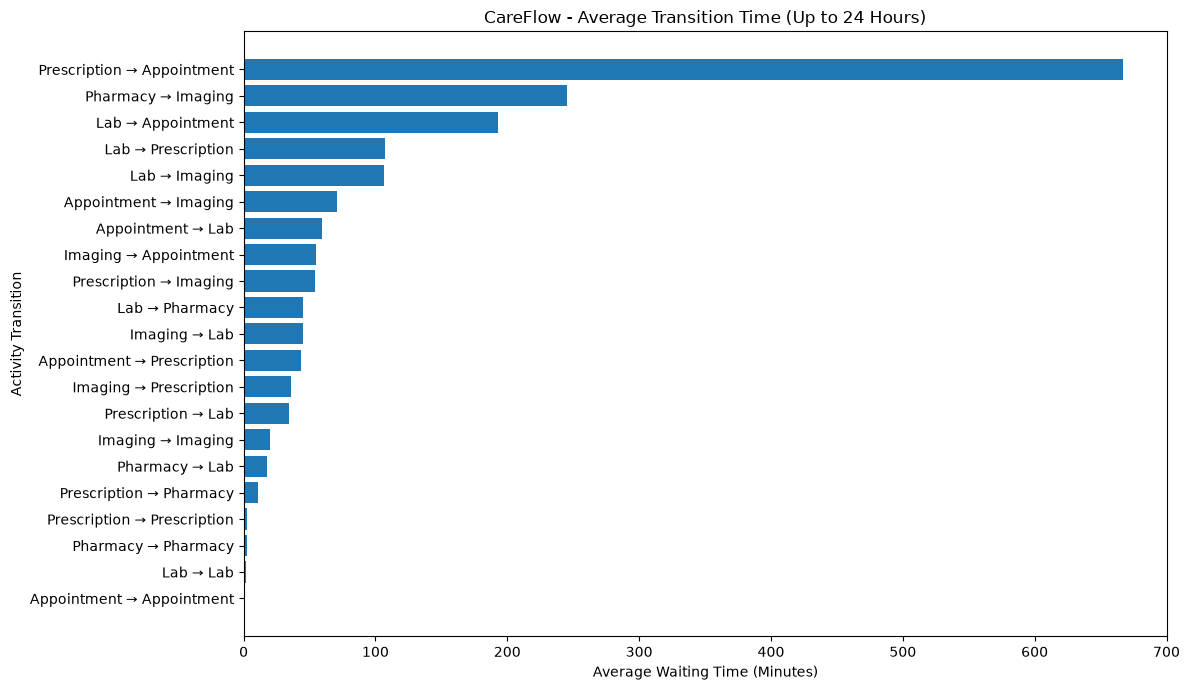

Transition waiting-time chart saved successfully!


In [10]:
plt.figure(figsize=(12, 7))

chart_data = filtered_summary.sort_values(
    "Average_Waiting_Time_Minutes",
    ascending=True
)

labels = (
    chart_data["Activity_Name"]
    + " → "
    + chart_data["Next_Activity"]
)

plt.barh(
    labels,
    chart_data["Average_Waiting_Time_Minutes"]
)

plt.xlabel("Average Waiting Time (Minutes)")
plt.ylabel("Activity Transition")
plt.title("CareFlow - Average Transition Time (Up to 24 Hours)")

plt.tight_layout()

plt.savefig(
    "careflow_transition_waiting_time_chart.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Transition waiting-time chart saved successfully!")

In [11]:
unusual_transitions.to_csv(
    "careflow_unusual_transition_gaps.csv",
    index=False
)

print("Unusual transition gaps saved successfully!")
print("Transitions above 24 hours:", len(unusual_transitions))

Unusual transition gaps saved successfully!
Transitions above 24 hours: 589


In [3]:
bottleneck_candidates = filtered_summary[
    filtered_summary["Transition_Count"] >= 100
].copy()

bottleneck_candidates = bottleneck_candidates.sort_values(
    "Average_Waiting_Time_Minutes",
    ascending=False
)

display(bottleneck_candidates)

bottleneck_candidates.to_csv(
    "careflow_bottleneck_candidates.csv",
    index=False
)

print("Bottleneck candidate analysis completed!")
print("Candidate transitions:", len(bottleneck_candidates))

,Activity_Name,Next_Activity,Transition_Count,Average_Waiting_Time_Minutes,Median_Waiting_Time_Minutes
2,Lab,Appointment,125,192.800000,158.0
3,Lab,Prescription,369,107.002710,33.0
4,Lab,Imaging,409,106.122249,52.0
5,Appointment,Imaging,1599,70.612883,46.0
6,Appointment,Lab,354,59.135593,29.5
7,Imaging,Appointment,288,55.135417,18.0
8,Prescription,Imaging,2850,53.849825,34.0
10,Imaging,Lab,614,44.894137,29.0
11,Appointment,Prescription,47630,43.196893,25.0
12,Imaging,Prescription,1662,35.589651,25.0


Bottleneck candidate analysis completed!
Candidate transitions: 17


In [2]:
import pandas as pd

filtered_summary = pd.read_csv(
    "careflow_process_performance_summary.csv"
)

print("Filtered summary loaded successfully!")
print("Rows:", len(filtered_summary))

display(filtered_summary.head())

Filtered summary loaded successfully!
Rows: 21


,Activity_Name,Next_Activity,Transition_Count,Average_Waiting_Time_Minutes,Median_Waiting_Time_Minutes
0,Prescription,Appointment,3,667.000000,556.0
1,Pharmacy,Imaging,1,245.000000,245.0
2,Lab,Appointment,125,192.800000,158.0
3,Lab,Prescription,369,107.002710,33.0
4,Lab,Imaging,409,106.122249,52.0


In [4]:
bottleneck_candidates = filtered_summary[
    filtered_summary["Transition_Count"] >= 100
].copy()

bottleneck_candidates = bottleneck_candidates.sort_values(
    "Average_Waiting_Time_Minutes",
    ascending=False
)

bottleneck_candidates.to_csv(
    "careflow_bottleneck_candidates.csv",
    index=False
)

print("Bottleneck candidate analysis completed!")
print("Candidate transitions:", len(bottleneck_candidates))

display(bottleneck_candidates)

Bottleneck candidate analysis completed!
Candidate transitions: 17


,Activity_Name,Next_Activity,Transition_Count,Average_Waiting_Time_Minutes,Median_Waiting_Time_Minutes
2,Lab,Appointment,125,192.800000,158.0
3,Lab,Prescription,369,107.002710,33.0
4,Lab,Imaging,409,106.122249,52.0
5,Appointment,Imaging,1599,70.612883,46.0
6,Appointment,Lab,354,59.135593,29.5
7,Imaging,Appointment,288,55.135417,18.0
8,Prescription,Imaging,2850,53.849825,34.0
10,Imaging,Lab,614,44.894137,29.0
11,Appointment,Prescription,47630,43.196893,25.0
12,Imaging,Prescription,1662,35.589651,25.0


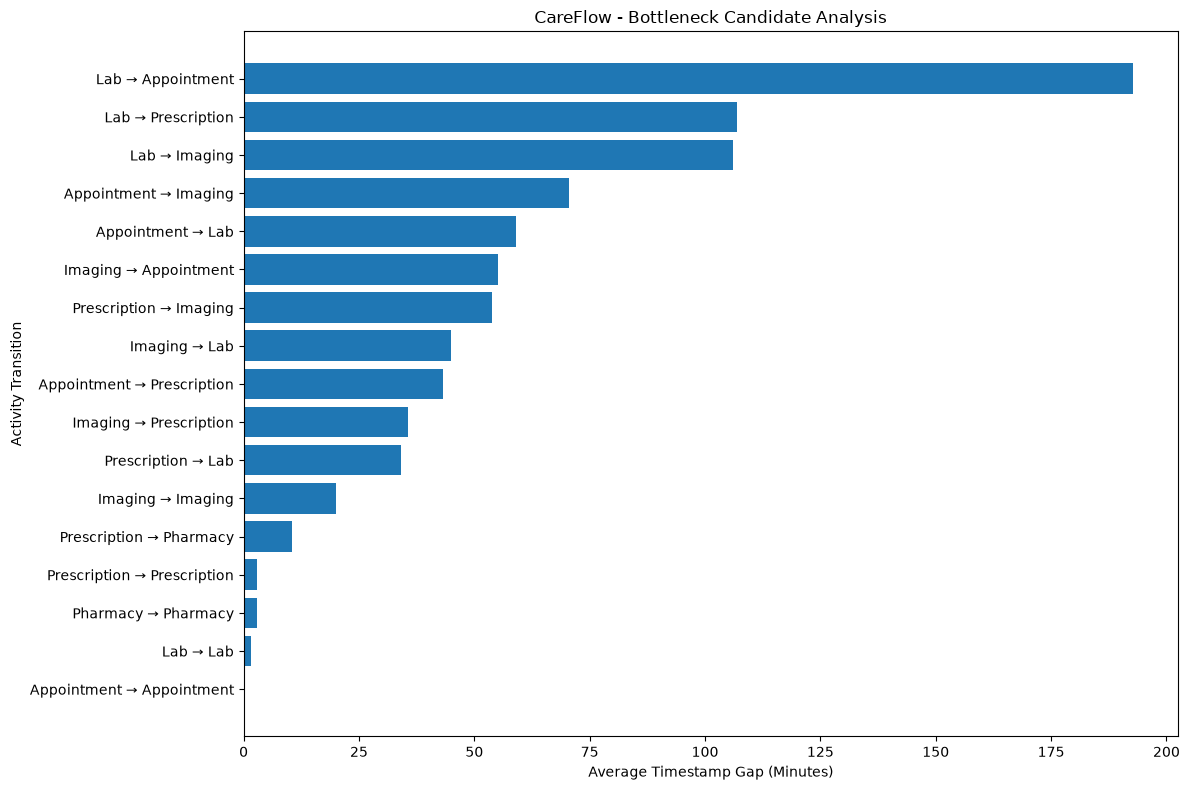

Bottleneck analysis chart saved successfully!


In [5]:
import matplotlib.pyplot as plt

chart_data = bottleneck_candidates.sort_values(
    "Average_Waiting_Time_Minutes",
    ascending=True
)

labels = (
    chart_data["Activity_Name"]
    + " → "
    + chart_data["Next_Activity"]
)

plt.figure(figsize=(12, 8))

plt.barh(
    labels,
    chart_data["Average_Waiting_Time_Minutes"]
)

plt.xlabel("Average Timestamp Gap (Minutes)")
plt.ylabel("Activity Transition")
plt.title("CareFlow - Bottleneck Candidate Analysis")

plt.tight_layout()

plt.savefig(
    "careflow_bottleneck_analysis_chart.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Bottleneck analysis chart saved successfully!")